# The data: a table and a map

<p class="nb-download">Run it yourself: <a href="_static/notebooks/data.ipynb" download>this notebook</a> · <a href="_static/geoai_hexagons.zip" download>all notebooks, the helpers and the data (zip)</a></p>

<img src="_static/figures/0_table_and_map.gif" class="wide" alt="Animation: each row of the table is one hexagon on the map">
<p class="slides-caption">The five rows of the table, one after the other, on the map.</p>

<div class="slides n1"><a href="_static/slides/words.png"><img src="_static/slides/words.png" alt="Lecture slide: From machine learning to GeoAI: a table, then a map"></a></div>
<p class="slides-caption">From the lecture <a href="https://introsda.readthedocs.io/en/latest/lessons/L10/intro-to-GeoAI-2.html">Introduction to GeoAI, part 2</a>. Click a slide to enlarge it.</p>

```{admonition} Question
:class: tip
What does one row of our table look like on the map?
```

**In this notebook:** 1 · load the table  2 · read five rows  3 · put them on the map  4 · see where the label comes from  5 · compare neighbours

## 1 · Load the table

The Helsinki region as 1,459 hexagons of the H3 grid (week 7), each about 0.57 km². One hexagon is one **row**. Everything comes from OpenStreetMap.

In [1]:
import numpy as np
import pandas as pd

import helpers as h

hexes, X, y, W = h.load()        # the table, the features, the labels, the neighbours
print(f"{len(hexes):,} hexagons, {X.shape[1]} features")
print(pd.Series(y).value_counts().to_string())

1,459 hexagons, 16 features
green          747
residential    569
work           143


- `X` · the **features**: 16 counts of points of interest (POIs) per hexagon, as `log(1 + count)`.
- `y` · the **label**: the land use, one of `green`, `residential`, `work`.
- `W` · which hexagons touch (the spatial weights matrix of week 3).

## 2 · Read five rows

Five hexagons that every notebook follows, and three of the 16 features.

In [2]:
five = h.five(hexes)             # place name -> row number
rows = hexes.loc[five.values, ["car", "play", "office", "poi_total", "landuse"]]
rows.index = five.index
rows

,car,play,office,poi_total,landuse
Otaniemi,92,2,15,305,work
Tikkurila,64,13,16,338,residential
Kontula,26,7,0,98,residential
Seurasaari,0,7,0,124,green
Nuuksio,1,7,0,13,green


In [3]:
if h.SAVE:    # the animation at the top of the page
    h.frames_gif(lambda k: h.table_and_map(hexes, five, k), [0, 1, 2, 3, 4, 5], "0_table_and_map.gif", ms=1800, hold_last=2)

`car` counts parking and fuel, `play` playgrounds and picnic sites, `office` offices. The counts are what we know about a place. The last column is what a model should predict.

All 16 counts of one row, the hexagon of the Otaniemi campus:

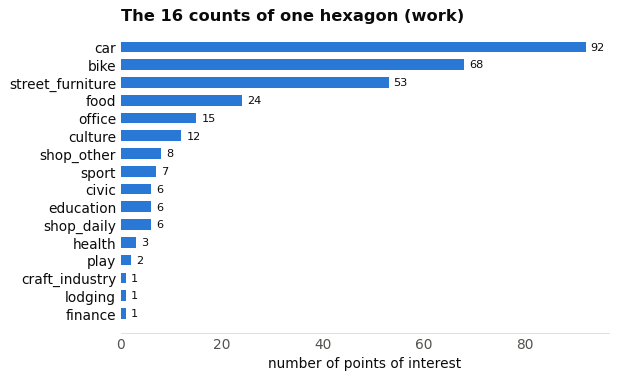

In [4]:
h.profile(hexes, five["Otaniemi"]);

## 3 · The same rows on the map

A table has no geography: shuffle its rows and nothing changes. On the map every row has a place.

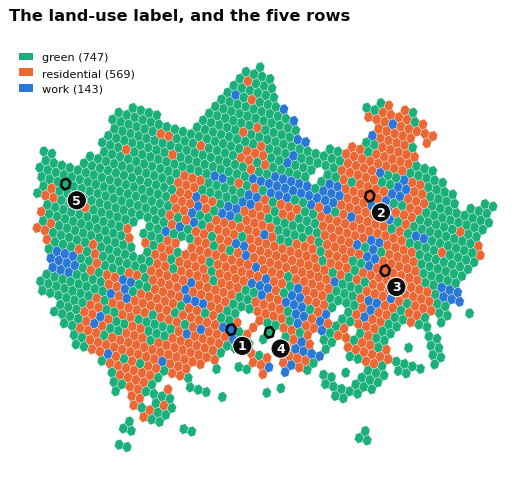

In [5]:
ax = h.map_classes(hexes, y, title="The land-use label, and the five rows", places=False)
h.number_hexagons(ax, hexes, five.values)

Point at a hexagon to read its row. Zoom in to see the streets and parks behind the counts.

<iframe src="_static/maps/hexagons.html" class="webmap" title="Interactive map of the hexagons"></iframe>

*Map data and background map © OpenStreetMap contributors.*

In [6]:
if h.SAVE:    # the interactive map of the website
    h.web_map(hexes, {"municipality": "municipality", "poi_total": "points of interest, all 16 kinds", "car": "parking and fuel",
                      "play": "playgrounds and picnic sites", "office": "offices", "food": "food places", "shop_daily": "daily shops",
                      "education": "schools"})

## 4 · The label is a rule

A hexagon holds several land uses and gets one name: at least 20% built-up land makes it `residential` or `work`, whichever covers more. Everything else is `green`. What if the rule were 10% or 30%?

In [7]:
for rule in (0.10, 0.30):
    changed = np.mean(h.label_with(hexes, rule) != y)
    print(f"{rule:.0%} rule: {changed:.0%} of the labels change")

10% rule: 13% of the labels change
30% rule: 12% of the labels change


**Result.** Another reasonable rule renames about one hexagon in eight. The label is a decision, not a measurement, so no model should reach 100%.

## 5 · Neighbours are alike

How often does a hexagon have the same label as a hexagon that touches it?

In [8]:
same = np.mean([np.mean(y[W[i].indices] == y[i]) for i in range(len(y)) if W[i].nnz])
chance = (pd.Series(y).value_counts(normalize=True) ** 2).sum()
print(f"same label as a neighbour: {same:.0%}     if labels were scattered at random: {chance:.0%}")

same label as a neighbour: 69%     if labels were scattered at random: 42%


In [9]:
assert (h.label_with(hexes, 0.20) == y).all()
h.note("dependence", {"same_as_neighbours": round(float(same), 2), "by_chance": round(float(chance), 2)})

**Result.** 69% against 42%: spatial dependence in one number (Tobler's first law, week 3). A hexagon without a label is not a hexagon about which we know nothing.

**Next:** [what learning is](learning), or straight to [supervised learning](supervised).